# Numerical Analysis
## Lab 1: Introduction to MATLAB and floating-point
*21/09/2026*

### Setup
Run this cell first: it selects a graphics toolkit that can draw inside the notebook (without it, plots fail with the `DISPLAY=''` error).

In [12]:
warning("off", "Octave:gnuplot-graphics");
graphics_toolkit("gnuplot");
%plot inline

---
### Exercise 1.1
Define the row vector

$$v_k = \left[1,\ 9,\ 25,\ \dots,\ (2k+1)^2\right] \in \mathbb{R}^{k+1}$$

with $k = 8$ using the following strategies:
1. using a `for` loop;
2. using one-shot vector syntax.

In [2]:
clear; close all
k = 8;

% 1) For loop strategy
vk = zeros(1, k+1);
fprintf("Loop strategy: \n");
tic
for ii = 0:k
  vk(ii+1) = (2*ii + 1)^2;
end
toc
vk

Loop strategy: 
Elapsed time is 0.0989699 seconds.
vk =

     1     9    25    49    81   121   169   225   289



In [3]:
% 2) Vector syntax
fprintf("Vector syntax: \n");
tic
vk = [1:2:2*k+1].^2;
toc
vk

Vector syntax: 
Elapsed time is 0.0543959 seconds.
vk =

     1     9    25    49    81   121   169   225   289



---
### Exercise 1.2
Define a function which, for an input value $k$, returns the corresponding vector $v_k$ as defined in the previous exercise.

In [ ]:
function vk = ex_1_2(k)
  vk = [1:2:2*k+1].^2;
end

In [ ]:
% Test the function
ex_1_2(8)

---
### Exercise 1.3
Define a script that generates a $10 \times 10$ matrix $A$ with random entries between $0$ and $1$. Then, extract and display the third column of $A$.

In [8]:
% Generate a 10x10 matrix A with random entries between 0 and 1
A = rand(3, 3);

% Extract the third column of A
col3 = A(:, 3);

% Display the third column
disp('The third column of A is:');
disp(col3);
disp('')
disp(A)

The third column of A is:
   0.8489
   0.6397
   0.1822

   0.5980   0.5319   0.8489
   0.9093   0.6549   0.6397
   0.1724   0.4014   0.1822


---
### Exercise 1.4
Define a script to create the following square matrix $A$ of size $2n \times 2n$, where $n$ is a user-defined natural number. Here an example for $n = 5$:

$$
A = \begin{pmatrix}
1&1&1&1&1&1&1&1&1&1\\
1&2&2&2&2&2&2&2&2&1\\
1&2&3&3&3&3&3&3&2&1\\
1&2&3&4&4&4&4&3&2&1\\
1&2&3&4&5&5&4&3&2&1\\
1&2&3&4&5&5&4&3&2&1\\
1&2&3&4&4&4&4&3&2&1\\
1&2&3&3&3&3&3&3&2&1\\
1&2&2&2&2&2&2&2&2&1\\
1&1&1&1&1&1&1&1&1&1
\end{pmatrix}
$$

By using the matrix $A$ and the command `spy`, plot a chessboard.

> **Note:** `input()` is not reliable inside a notebook, so here $N$ is set directly in the code. Change its value and re-run the cells.

In [9]:
% Internal matrix
clear all;

N = 5;   % in a .m script you can use: N = input('Insert a number: ');

A = ones(2*N);
tic
for i = 2:2*N-1
    A(i:2*N-(i-1), i:2*N-(i-1)) = i;
end
toc
A

Elapsed time is 0.0928831 seconds.
A =

   1   1   1   1   1   1   1   1   1   1
   1   2   2   2   2   2   2   2   2   1
   1   2   3   3   3   3   3   3   2   1
   1   2   3   4   4   4   4   3   2   1
   1   2   3   4   5   5   4   3   2   1
   1   2   3   4   5   5   4   3   2   1
   1   2   3   4   4   4   4   3   2   1
   1   2   3   3   3   3   3   3   2   1
   1   2   2   2   2   2   2   2   2   1
   1   1   1   1   1   1   1   1   1   1



In [10]:
% Chessboard: set to zero the entries where i+j is even
for i = 1:2*N
    for j = 1:2*N
        if floor((i+j)/2)*2 == i+j
            A(i,j) = 0;
        end
    end
end

A

A =

   0   1   0   1   0   1   0   1   0   1
   1   0   2   0   2   0   2   0   2   0
   0   2   0   3   0   3   0   3   0   1
   1   0   3   0   4   0   4   0   2   0
   0   2   0   4   0   5   0   3   0   1
   1   0   3   0   5   0   4   0   2   0
   0   2   0   4   0   4   0   3   0   1
   1   0   3   0   3   0   3   0   2   0
   0   2   0   2   0   2   0   2   0   1
   1   0   1   0   1   0   1   0   1   0



In [ ]:
% Chessboard with scatter
[X, Y] = meshgrid(linspace(1, 2*N, 2*N));

R = X(A == 0);
C = Y(A == 0);

scatter(R, C, 1000, 'sk', 'filled')
axis([0 2*N+1 0 2*N+1])

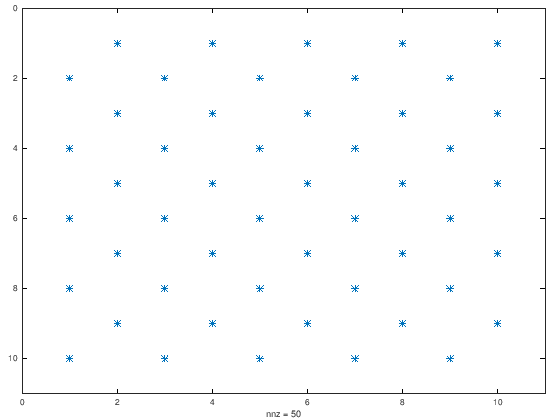

In [14]:
% Chessboard with spy, as requested in the text
%spy(A == 0)
spy(A)

---
### Exercise 1.5
Find the machine epsilon by implementing an *ad hoc* procedure. Comment and justify the obtained results.

The idea: start from $\varepsilon = 1/2$ and keep halving it as long as $1 + \varepsilon > 1$ in floating-point arithmetic. The last value that still satisfies the condition is the machine epsilon.

In [ ]:
% Pay attention: we use EPS and not eps, to avoid overwriting the built-in eps
k = 0;
EPS = 1/2;
while (1 + EPS) > 1
  EPS_old = EPS;    % keep track of the value
  EPS = EPS / 2;
  k = k + 1;
end
EPS_old   % computed with the ad-hoc procedure
k         % number of iterations = number of bits of the mantissa (IEEE 754 double precision)
eps       % built-in value

**Comment.** In IEEE 754 double precision the mantissa has $52$ stored bits, so the machine epsilon is

$$\varepsilon_{\text{mach}} = 2^{-52} \approx 2.22 \times 10^{-16}.$$

The loop runs $k = 52$ times: after that $\varepsilon = 2^{-53}$, and $1 + 2^{-53}$ is rounded back to $1$, so the condition fails. `EPS_old` $= 2^{-52}$ is the last value for which $1 + \varepsilon > 1$, and it coincides with the built-in `eps`.

---
### Exercise 1.6
Compare the results of the following code segments:

**Code A**
```
x = 0;
while (x ~= 1)
  x = x + 1/16
end
```

**Code B**
```
x = 0;
while (x ~= 1)
  x = x + 0.1
end
```

In [ ]:
% Code A
xA = 0;
iterA = 0;
while (xA ~= 1)
  xA = xA + 1/16
  iterA = iterA + 1
end

In [ ]:
% Code B
% A counter has been inserted to stop the infinite loop.
% The ';' avoids printing 100 lines: only the final values are shown.
xB = 0;
iterB = 0;
while (xB ~= 1 && iterB < 100)
  xB = xB + 0.1;
  iterB = iterB + 1;
end
xB
iterB

**Comment.** $1/16 = 2^{-4}$ is exactly representable in binary, so after $16$ steps $x$ is exactly $1$ and Code A stops. On the contrary, $0.1$ has an infinite binary expansion

$$0.1 = (0.0\overline{0011})_2,$$

so it is stored with a rounding error that accumulates: $x$ never equals $1$ exactly and Code B would loop forever (here it stops only because of the counter).

#### Pay attention!
Floating-point addition is **not associative**:

$$(a + b) + c \neq (a + c) + b \quad \text{in general.}$$

In [ ]:
realmax
a = 1.0e+308;
b = -a;
c = 1.1e+308;
(a + b) + c   % expected result
(a + c) + b   % overflow: a + c > realmax

#### How is it possible to fix Code B?
Never compare floating-point numbers with `==` or `~=`: use a tolerance, $|x - 1| < \text{tol}$.

In [ ]:
xC = 0;
iterC = 0;
while (abs(xC - 1) >= 2*eps)
  xC = xC + 0.1
  iterC = iterC + 1
end

---
### Exercise 1.7
Consider the following function

$$f(x) = \frac{e^x - 1}{x}.$$

**a)** Evaluate $f(x)$ for values of $x$ around zero (try with $x_k = 10^{-k}$, $k \in [1, 20]$). What do you obtain? Explain the results.

In [ ]:
k = [1:20]';
x = 10.^(-k);
f = @(x) (exp(x) - 1) ./ x;
format long
[k x f(x)]

**Comment.** The exact limit is $\lim_{x \to 0} f(x) = 1$, but the computed values deteriorate as $x$ decreases. For small $x$, $e^x \approx 1$ and the subtraction $e^x - 1$ suffers from **catastrophic cancellation**: the significant digits cancel and the relative error explodes. When $x$ is below $\varepsilon_{\text{mach}}/2$, `exp(x)` is rounded to exactly $1$ and $f(x) = 0$.

**b)** Propose an approach for fixing the problem. *(Hint: use Taylor expansions to get an approximation of $f(x)$ around $x = 0$.)*

From $e^x = \sum_{k \ge 0} \frac{x^k}{k!}$ we get

$$f(x) = \sum_{k=0}^{\infty} \frac{x^k}{(k+1)!} = 1 + \frac{x}{2} + \frac{x^2}{6} + \frac{x^3}{24} + \frac{x^4}{120} + \dots$$

which involves no subtraction and is therefore stable near $0$.

In [ ]:
f_taylor_5 = @(x) 1 + 1/2*x + 1/6*x.^2 + 1/24*x.^3 + 1/120*x.^4;

[k x f(x) f_taylor_5(x)]

**c)** How many terms in the Taylor expansion are needed to get double precision accuracy ($16$ decimal digits) for all $x \in [0, 1/2]$?

Truncating at degree $n$, the Lagrange remainder gives

$$\left| f(x) - \sum_{k=0}^{n} \frac{x^k}{(k+1)!} \right| = \frac{e^{\xi}\, x^{n+1}}{(n+2)!} \le \frac{e^{1/2} \left(\tfrac{1}{2}\right)^{n+1}}{(n+2)!}, \qquad \xi \in (0, x).$$

In [ ]:
format short e
n = [1:20]';
err = 1./factorial(n+2) .* (0.5).^(n+1) .* exp(0.5);

[n err]

% Smallest degree with error below machine epsilon
n_min = n(find(err < eps, 1))

The bound drops below $\varepsilon_{\text{mach}}$ for $n = 13$: a polynomial of degree $13$, i.e. $14$ terms of the expansion, is enough.